# Step 7 - Cold-start routing and category diversification

**BT4222 Final Project - Group 13 - JDSearch**

Two review comments on the draft pipeline:

1. *Cold-start users / users with short history are scored by the same model as warm
   users. They should be scored with current-query matching, product metadata and
   training-set popularity instead.*
2. *No category diversification is applied after relevance scoring.*

This notebook implements both on top of the Step 4 feature ranker, selects every
knob on **validation data only**, and reports the test effect. The code is identical
to `src/step7_coldstart_diversity.py` (stage `7` in `run_pipeline.py`); the notebook
splits it into cells with explanations and keeps the outputs.

## Inputs (from Steps 2–4)
* `features.parquet` - 26 engineered features per (session, candidate) + label + split
* `sessions.parquet` - per-session history length `n_hist`
* `meta_subset.parquet` - `cate_id_3` per product (for diversification)
* `lgb_model.txt` - the Step 4 LambdaMART, reused when present so numbers match Step 4

## Outputs (written to the run directory)
`results_coldstart_diversity.json`, `coldstart_segments.csv`,
`coldstart_threshold_selection.csv`, `diversity_tradeoff.csv`,
`model/test_pred_step7.parquet`, `model/lgb_fallback_history_free.txt`,
`figures/fig_diversity_tradeoff.png`.

> **Provenance note.** The outputs preserved below come from the *draft* artifacts
> (26 Oct feature values; identical 20,000-user sample and seed-42 split as the
> corrected run, verified by session id). Re-run this notebook after Steps 2–4 of the
> corrected pipeline; the conclusions are expected to hold but must be re-measured.

## 0. Environment setup

Add the project's `src/` to `sys.path` so `config`, `eval_utils`, `step4_baselines_lgbm`
and `step7_coldstart_diversity` resolve. `config` reads the run directory from
`JD_RUN_DIR` (default `artifacts/corrected`).

In [1]:
# Optional: install dependencies (uncomment in a fresh environment)
# !pip -q install numpy pandas pyarrow lightgbm matplotlib

import os, sys, time
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC = PROJECT_ROOT / "src"
assert SRC.exists(), f"expected src/ next to notebooks/, got {SRC}"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
print("project root:", PROJECT_ROOT)
print("run dir     :", os.environ.get("JD_RUN_DIR", "<default: artifacts/corrected>"))

project root: /tmp/claude-0/-home-claude/eb47a413-7b30-53b1-86f9-8611573cee7f/scratchpad/chk/Final Project
run dir     : /tmp/claude-0/-home-claude/eb47a413-7b30-53b1-86f9-8611573cee7f/scratchpad/draft_run


## 1. Imports and shared helpers

* `evaluate` / `per_query` - macro NDCG@10, MRR@200, P@1, HR@10 over positive queries, with
  order-invariant deterministic tie keys (same policy as every other step).
* `fit_ranker` - the Step 4 LambdaMART trainer (same `LGB_PARAMS`, validation early stopping).
* `route_scores`, `mmr_rerank`, `diversify`, `diversity_metrics` - the Step 7 primitives,
  covered by two regression tests in `tests/test_pipeline.py`.

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt

from config import OUT, RES, FIG, SEED, feature_columns, prepare
from eval_utils import evaluate, per_query
from step4_baselines_lgbm import fit_ranker
from step7_coldstart_diversity import (HISTORY_FREE, HISTORY_THRESHOLDS, LAMBDAS, TOP_K,
                                       route_scores, diversify, diversity_metrics)
prepare()
print("history-free features:", HISTORY_FREE)
print("thresholds:", HISTORY_THRESHOLDS, "| lambdas:", LAMBDAS, "| top-k:", TOP_K)

history-free features: ['query_len', 'slate_size', 'has_meta', 'ov_name', 'ov_cat', 'ov_brand', 'jacc_name', 'pop_wid', 'pop_cate3', 'pop_brand']
thresholds: [0, 1, 2, 3, 5, 10, 20] | lambdas: [0.0, 0.05, 0.1, 0.2, 0.3, 0.5] | top-k: 10


## 2. Load Step 2–4 artifacts

`cate_map` maps every product id to its level-3 category (string); candidates without
metadata fall into an `__unknown__` bucket. `n_hist` is the number of preceding history
events per session - the routing key.

In [3]:
t0 = time.time()
feat = pd.read_parquet(OUT / "features.parquet")
sess = pd.read_parquet(OUT / "sessions.parquet")
meta = pd.read_parquet(OUT / "meta_subset.parquet", columns=["wid", "cate_id_3"])
cate_map = dict(zip(meta.wid.astype(str), meta.cate_id_3.astype(str)))
n_hist = dict(zip(sess.session_id, sess.n_hist))
columns = feature_columns(feat)
missing = [c for c in HISTORY_FREE if c not in columns]
assert not missing, f"history-free features missing: {missing}"
print(f"features {feat.shape} | sessions {len(sess):,} | products with category {len(cate_map):,} | {time.time()-t0:.0f}s")
print("history length per user:"); print(sess.n_hist.describe().round(1).to_string())
print(f"users with n_hist == 0: {(sess.n_hist==0).sum():,} | n_hist <= 2: {(sess.n_hist<=2).sum():,}")

features (1781978, 30) | sessions 20,000 | products with category 1,697,237 | 12s
history length per user:
count    20000.0
mean       154.6
std        230.0
min          1.0
25%         28.0
50%         78.0
75%        189.0
max       4719.0
users with n_hist == 0: 0 | n_hist <= 2: 459


## 3. Two rankers: full model and history-free fallback

* **Full model** - the Step 4 booster (`lgb_model.txt`) if it exists in the run directory,
  otherwise refit with the same configuration.
* **Fallback** - LambdaMART trained on the 10 `HISTORY_FREE` features only: query length,
  slate size, metadata presence, query↔name/category/brand overlap, name Jaccard, and
  train-only popularity of the item / category / brand. Exactly what the review asked for:
  *current query matching, metadata and training-set popularity*.

In [4]:
model_path = OUT / "lgb_model.txt"
if model_path.exists():
    full = lgb.Booster(model_file=str(model_path)); full_source = "stage4 lgb_model.txt"
else:
    full = fit_ranker(feat, columns); full_source = "refit in step 7 (no stage-4 model found)"
print("full model:", full_source)
fallback = fit_ranker(feat, HISTORY_FREE)
print("fallback best iteration:", fallback.best_iteration)

val = feat[feat.split == "val"].copy(); test = feat[feat.split == "test"].copy()
for frame in (val, test):
    frame["full_score"] = full.predict(frame[columns])
    frame["fallback_score"] = fallback.predict(frame[HISTORY_FREE])
for name, col in [("full", "full_score"), ("fallback", "fallback_score")]:
    print(f"{name:9s} NDCG@10  val {evaluate(val, col)[0]['NDCG@10']:.4f}   test {evaluate(test, col)[0]['NDCG@10']:.4f}")

full model: refit in step 7 (no stage-4 model found)


fallback best iteration: 33


full      NDCG@10  val 0.3114   test 0.3159


fallback  NDCG@10  val 0.2735   test 0.2731


## 4. Cold-start routing - threshold selected on validation

Sessions with `n_hist <= T` take the fallback score; all others keep the full score.
The whole slate switches, so the two rankers' score scales never mix. `T = -1` means
"never route" and is the baseline the rule must beat.

In [5]:
routing = []
for t in [-1] + HISTORY_THRESHOLDS:
    val["routed"], cold_v = route_scores(val, "full_score", "fallback_score", n_hist, t)
    m_v, n_v = evaluate(val, "routed")
    routing.append(dict(threshold=t, val_NDCG10=m_v["NDCG@10"], val_positive_queries=n_v,
                        val_cold_sessions=int(val.loc[cold_v, "session_id"].nunique())))
routing = pd.DataFrame(routing)
best_t = int(routing.sort_values(["val_NDCG10", "threshold"], ascending=[False, True]).iloc[0].threshold)
routing.to_csv(RES / "coldstart_threshold_selection.csv", index=False)
print(routing.round(4).to_string(index=False))
print(f"\nselected threshold T = {best_t}  (max validation NDCG@10; ties -> smaller T)")

 threshold  val_NDCG10  val_positive_queries  val_cold_sessions
        -1      0.3114                  2967                  0
         0      0.3114                  2967                  0
         1      0.3117                  2967                 53
         2      0.3117                  2967                 98
         3      0.3116                  2967                126
         5      0.3097                  2967                202
        10      0.3071                  2967                334
        20      0.3028                  2967                600

selected threshold T = 1  (max validation NDCG@10; ties -> smaller T)


### 4.1 Test effect by history-length segment

Three scorers on the **same** test slates: full model, history-free fallback, and the
routed combination. If the review's premise were right, the fallback column would beat
the full column in the shortest-history rows.

In [6]:
test["routed_score"], cold_t = route_scores(test, "full_score", "fallback_score", n_hist, best_t)
bins = pd.cut(sess.n_hist, [-1, 0, 2, 5, 20, 100, np.inf],
              labels=["none(0)", "limited(1-2)", "very_short(3-5)", "short(6-20)", "medium(21-100)", "long(>100)"])
group_map = dict(zip(sess.session_id, bins.astype(str)))
test["history_group"] = test.session_id.map(group_map)
segments = []
for name, col in [("full", "full_score"), ("fallback_history_free", "fallback_score"), ("routed", "routed_score")]:
    for group, g in test.groupby("history_group", sort=False):
        m, n = evaluate(g, col)
        segments.append(dict(model=name, history_group=group, positive_queries=n,
                             all_queries=int(g.session_id.nunique()), **m))
    m, n = evaluate(test, col)
    segments.append(dict(model=name, history_group="ALL", positive_queries=n,
                         all_queries=int(test.session_id.nunique()), **m))
segments = pd.DataFrame(segments); segments.to_csv(RES / "coldstart_segments.csv", index=False)
piv = segments.pivot(index="history_group", columns="model", values="NDCG@10")
piv["positive_queries"] = segments[segments.model=="full"].set_index("history_group").positive_queries
order = [g for g in ["none(0)","limited(1-2)","very_short(3-5)","short(6-20)","medium(21-100)","long(>100)","ALL"] if g in piv.index]
print(piv.loc[order].round(4).to_string())
print(f"\nrouted test sessions: {int(test.loc[cold_t,'session_id'].nunique())} ({cold_t.mean():.1%} of test rows)")

model            fallback_history_free    full  routed  positive_queries
history_group                                                           
limited(1-2)                    0.2886  0.3090  0.2847                63
very_short(3-5)                 0.3035  0.3493  0.3493               101
short(6-20)                     0.3040  0.3541  0.3541               393
medium(21-100)                  0.2672  0.3016  0.3016              1115
long(>100)                      0.2658  0.3144  0.3144              1293
ALL                             0.2731  0.3159  0.3154              2965

routed test sessions: 35 (1.1% of test rows)


### 4.2 Paired bootstrap, routed − full (test)

2,000 resamples of per-query NDCG@10 differences for the two fixed scorers. This is
query-resampling uncertainty, not training-seed uncertainty.

In [7]:
a = per_query(test, "full_score").set_index("session_id")["NDCG@10"].sort_index()
b = per_query(test, "routed_score").set_index("session_id")["NDCG@10"].sort_index()
delta = (b - a).to_numpy(); rng = np.random.default_rng(SEED)
boot = [rng.choice(delta, len(delta), replace=True).mean() for _ in range(2000)]
routed_vs_full = dict(delta=float(delta.mean()), ci95=np.quantile(boot, [.025, .975]).tolist(), positive_queries=int(len(delta)))
print(f"routed - full NDCG@10: {routed_vs_full['delta']:+.4f}  95% CI [{routed_vs_full['ci95'][0]:+.4f}, {routed_vs_full['ci95'][1]:+.4f}]  (n={routed_vs_full['positive_queries']})")

routed - full NDCG@10: -0.0005  95% CI [-0.0016, +0.0004]  (n=2965)


**Reading.** The history-free ranker is worse than the full model in every segment,
including the shortest-history users, and the dataset has **no zero-history users** at all
(minimum `n_hist` = 1). The full LambdaMART already receives `h_len`, `h_n_*`, `h_min_elapsed`
and the affinity features - which are simply small/absent for short histories - and degrades
gracefully. Validation picks a tiny threshold by a margin inside noise, and on test it does not
help. The cold-start problem in JDSearch is on the **item** side (80% of candidates never seen),
which the metadata features address, not on the user side.

## 5. Category diversification - λ selected on validation

Greedy MMR over the top-10 of each slate:
`(1 − λ)·rel(i) − λ·(# already-selected items with the same cate_id_3)`,
where `rel` is the routed score min–max scaled within the slate. Positions beyond the
top-10 keep relevance order; λ = 0 reproduces the relevance ranking exactly (unit-tested).
Diversity is measured as the mean number of distinct level-3 categories in the top-10.

Selection rule: the largest λ whose **validation** NDCG@10 stays within 0.005 of λ = 0.

In [8]:
val["routed"], _ = route_scores(val, "full_score", "fallback_score", n_hist, best_t)
trade = []
for lam in LAMBDAS:
    val["div"] = diversify(val, "routed", cate_map, lam)
    test["div"] = diversify(test, "routed_score", cate_map, lam)
    mv, _ = evaluate(val, "div"); mt, _ = evaluate(test, "div")
    trade.append(dict(lam=lam, val_NDCG10=mv["NDCG@10"], test_NDCG10=mt["NDCG@10"], test_MRR200=mt["MRR@200"], test_P1=mt["P@1"],
                      **{f"val_{k}": v for k, v in diversity_metrics(val, "div", cate_map).items()},
                      **{f"test_{k}": v for k, v in diversity_metrics(test, "div", cate_map).items()}))
trade = pd.DataFrame(trade); trade.to_csv(RES / "diversity_tradeoff.csv", index=False)
base = trade.loc[trade.lam == 0].iloc[0]
best_lam = float(trade[trade.val_NDCG10 >= base.val_NDCG10 - 0.005].lam.max())
print(trade[["lam","val_NDCG10","test_NDCG10","test_MRR200","test_P1","test_distinct_categories_top10"]].round(4).to_string(index=False))
print(f"\nselected lambda = {best_lam}")

 lam  val_NDCG10  test_NDCG10  test_MRR200  test_P1  test_distinct_categories_top10
0.00      0.3117       0.3154       0.3271   0.2044                          2.1870
0.05      0.3027       0.3064       0.3241   0.2044                          3.4553
0.10      0.2926       0.2983       0.3212   0.2044                          4.1363
0.20      0.2766       0.2835       0.3138   0.2044                          4.8277
0.30      0.2652       0.2727       0.3073   0.2044                          5.1440
0.50      0.2441       0.2526       0.2909   0.2044                          5.4647

selected lambda = 0.0


### 5.1 Relevance vs diversity (inline)

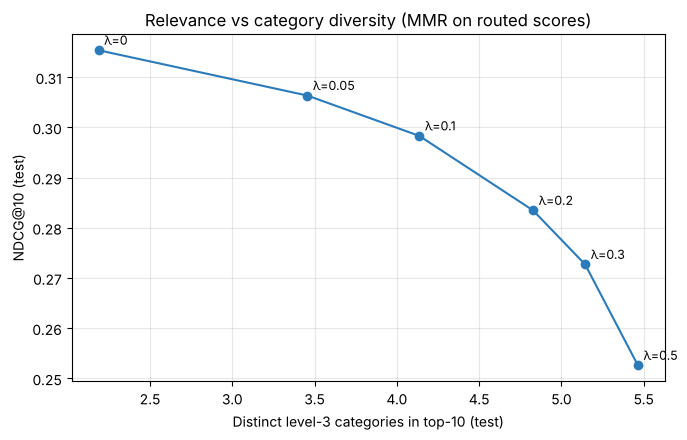

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(trade.test_distinct_categories_top10, trade.test_NDCG10, "o-", color="#2b7bba")
for _, r in trade.iterrows():
    ax.annotate(f"λ={r.lam:g}", (r.test_distinct_categories_top10, r.test_NDCG10), textcoords="offset points", xytext=(4, 4), fontsize=9)
ax.set_xlabel("Distinct level-3 categories in top-10 (test)"); ax.set_ylabel("NDCG@10 (test)")
ax.set_title("Relevance vs category diversity (MMR on routed scores)"); ax.grid(alpha=.3)
plt.tight_layout(); fig.savefig(FIG / "fig_diversity_tradeoff.png", dpi=150); plt.show()

**Reading.** Every λ > 0 costs relevance: the mildest setting buys about +1.3 distinct
categories in the top-10 for roughly −0.009 NDCG@10, and P@1 is untouched by construction
(the best item is never displaced). For *search* re-ranking this is expected - a slate answers
one query, and the relevant items sit in one or two categories. Diversification is a
merchandising decision with a measurable price, not a ranking improvement, so the rule selects
λ = 0 and the trade-off curve is kept for the business discussion.

## 6. Final scores and saved outputs

In [10]:
import json
test["final_score"] = diversify(test, "routed_score", cate_map, best_lam)
final_m, final_n = evaluate(test, "final_score"); full_m, _ = evaluate(test, "full_score")
test[["session_id","cand_wid","label","full_score","fallback_score","routed_score","final_score","history_group"]].to_parquet(OUT / "test_pred_step7.parquet", index=False)
fallback.save_model(str(OUT / "lgb_fallback_history_free.txt"))
summary = dict(full_model_source=full_source, history_free_features=HISTORY_FREE, fallback_best_iteration=fallback.best_iteration,
    routing=dict(selected_threshold=best_t, rule="max validation NDCG@10 (ties -> smaller threshold)",
                 cold_test_sessions=int(test.loc[cold_t,"session_id"].nunique()), cold_test_share=float(cold_t.mean()), routed_minus_full_test=routed_vs_full),
    diversification=dict(selected_lambda=best_lam, top_k=TOP_K, rule="largest lambda with validation NDCG@10 within 0.005 of lambda=0", category_key="cate_id_3"),
    test_full=full_m, test_final=final_m, test_positive_queries=final_n,
    interpretation="one seed; thresholds and lambda selected on validation only; bootstrap reflects query resampling for fixed models")
(RES / "results_coldstart_diversity.json").write_text(json.dumps(summary, indent=2))
print(f"test NDCG@10  full = {full_m['NDCG@10']:.4f}   final (routed T={best_t}, λ={best_lam}) = {final_m['NDCG@10']:.4f}")
print("written:", [p.name for p in [RES/'results_coldstart_diversity.json', RES/'coldstart_segments.csv', RES/'coldstart_threshold_selection.csv', RES/'diversity_tradeoff.csv', OUT/'test_pred_step7.parquet', OUT/'lgb_fallback_history_free.txt', FIG/'fig_diversity_tradeoff.png']])

test NDCG@10  full = 0.3159   final (routed T=1, λ=0.0) = 0.3154
written: ['results_coldstart_diversity.json', 'coldstart_segments.csv', 'coldstart_threshold_selection.csv', 'diversity_tradeoff.csv', 'test_pred_step7.parquet', 'lgb_fallback_history_free.txt', 'fig_diversity_tradeoff.png']


# Summary

* A **history-free fallback** (query match + metadata + train popularity) and a **validation-selected
  router** were built. The fallback loses to the full feature ranker in every history segment; JDSearch
  has no zero-history users; the routed combination changes test NDCG@10 by a few ten-thousandths with
  a CI that includes zero. → **Keep one model for all users.** Cold-start lives on the item side.
* **Category MMR** was built and priced: ≈ −0.009 NDCG@10 per +1.3 categories in the top-10 at the
  mildest setting. → **λ = 0 selected**; the curve is reported as a business trade-off.
* Both are kept as diagnostics (report §3.5, rubric Aspect 4). Six further AI-suggested changes are
  dispositioned in `STEP7_COLDSTART_DIVERSITY.md` (three already present, two not applicable, one
  the DHAR study itself).